# Exercise 4 - Effect of model width and depth (CIFAR-10)

**PUSL3123 AI and Machine Learning - Assessment 1**

**Aim:** vary the width (kernels per block) and depth (convolutional blocks) of the CNN and measure the effect on accuracy, training behaviour, overfitting and computational cost.

**Contents**
1. Setup and configuration
2. Data preparation (standard partitions, validation split, class distribution)
3. Helper functions (training, evaluation, plotting, multi-seed protocol)
4. Model: parametrised CNN and complexity
5. Training
6. Validation loss curves
7. Final evaluation (summary table and baseline check)
8. Width and depth figures
9. Discussion
10. Save results
11. Extension (outside the main protocol): learning rate for wider models

**How to run:** `pip install -r requirements.txt`, then *Run All*. Set the environment variable `QUICK_RUN=1` for a 2-epoch smoke test. The dataset downloads automatically into `data/`. Run `Ex3_Regularisation.ipynb` first so that the baseline check in Section 7 can compare with `results/ex3_regularisation.json`. The full notebook trains 30 models: 21 main runs (7 configurations x 3 seeds, learning rate 1e-3) + 9 extension runs (3 configurations x 3 seeds, learning rate 3e-4).

## 1. Setup and configuration

All four notebooks share the same configuration (seed, validation size, batch size, learning rate, epochs) so that results are directly comparable.

In [1]:
import os, json, time, random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision

# ---------------------------------------------------------------------------
# Configuration -- identical in all four notebooks so that results are comparable
# ---------------------------------------------------------------------------
SEED          = 42        # default run seed: weight initialisation, augmentation and batch shuffling
SPLIT_SEED    = 42        # train/validation split: identical for every experiment and every run
SEEDS         = (42, 43, 44)   # run seeds for the multi-seed experiments (Exercises 3 and 4)
VAL_SIZE      = 5_000     # validation images held out from the 50,000 training images
BATCH_SIZE    = 128
LEARNING_RATE = 1e-3
EPOCHS        = 2 if os.environ.get("QUICK_RUN") else 30   # set QUICK_RUN=1 for a 2-epoch smoke test
DATA_DIR      = "data"
RESULTS_DIR   = "results"
FIG_DIR       = os.path.join(RESULTS_DIR, "figures")
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ("aeroplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

os.makedirs(FIG_DIR, exist_ok=True)

def set_seed(seed=SEED):
    """Seed one run: weight initialisation plus dropout and augmentation randomness."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only")
print(f"Epochs: {EPOCHS} | batch size: {BATCH_SIZE} | learning rate: {LEARNING_RATE} | seed: {SEED}")

PyTorch 2.5.1+cu121 | torchvision 0.20.1+cu121
Device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU
Epochs: 30 | batch size: 128 | learning rate: 0.001 | seed: 42


## 2. Data preparation

* CIFAR-10 is loaded with `torchvision.datasets.CIFAR10` using the **standard partitions**: 50,000 training images and 10,000 test images.
* The test partition is kept completely separate: it is **not** used for training, hyper-parameter tuning or model selection.
* A **validation set of 5,000 images is held out from the 50,000 training images** with a fixed seed (`SPLIT_SEED`), leaving 45,000 images for training. The same split is used in every experiment.
* Images are decoded once into a single `uint8` tensor that lives on `DEVICE` for the rest of the notebook. Each minibatch is normalised on the fly (see `GPULoader` below) with the per-channel mean and standard deviation of the full 50,000-image training partition, computed before the 5,000-image validation split is held out; including those images has a negligible effect, and the test set is not used, which avoids the per-sample CPU transforms and `DataLoader` worker overhead that otherwise dominate training time. No data augmentation is used in this exercise.

In [2]:
# Per-channel mean / std of the full 50,000-image CIFAR-10 training partition (computed before the
# validation split is held out; the effect is negligible and the test set is not used)
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
MEAN_T = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_T  = torch.tensor(STD,  device=DEVICE).view(1, 3, 1, 1)

class GPULoader:
    """Minibatch iterator over images held entirely on DEVICE as a single uint8 tensor.

    Keeping a whole partition resident on DEVICE and normalising per batch -- instead of per-sample
    disk reads and CPU transforms behind a `DataLoader` -- removes the CPU bottleneck in data loading.
    Shuffling uses a seeded CPU generator so that the epoch order is reproducible; `augment`, if given,
    is applied to the already-normalised batch on the GPU (used from Exercise 3 onwards).
    """
    def __init__(self, images, targets, batch_size, shuffle, seed=SEED, augment=None):
        """Store the partition tensors and create the seeded shuffling generator."""
        self.images, self.targets = images, targets   # uint8 (N,3,32,32) / int64 (N,), both on DEVICE
        self.batch_size, self.shuffle, self.augment = batch_size, shuffle, augment
        self.generator = torch.Generator().manual_seed(seed) if shuffle else None

    def __iter__(self):
        """Yield normalised (and optionally augmented) minibatches, reshuffled each epoch if `shuffle`."""
        n = self.images.size(0)
        order = torch.randperm(n, generator=self.generator) if self.shuffle else torch.arange(n)
        order = order.to(self.images.device)
        for start in range(0, n, self.batch_size):
            idx = order[start:start + self.batch_size]
            x = (self.images[idx].float() / 255 - MEAN_T) / STD_T
            if self.augment is not None:
                x = self.augment(x)
            yield x, self.targets[idx]

    def __len__(self):
        """Number of minibatches per epoch (the last one may be smaller)."""
        return (self.images.size(0) + self.batch_size - 1) // self.batch_size


_partitions = {}   # decoded tensors, cached so that repeated build_data calls never reload from disk

def load_partitions():
    """Decode CIFAR-10 into DEVICE memory once per kernel and apply the fixed train/validation split.
    Standard partitions (50,000 train / 10,000 test); VAL_SIZE images are held out from the training
    images using SPLIT_SEED, so the split is identical for every experiment and every run seed."""
    if not _partitions:
        train_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  download=True)
        test_raw  = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)

        def as_device_tensors(ds):
            """Convert a torchvision CIFAR-10 dataset to uint8 image and int64 label tensors on DEVICE."""
            images = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous().to(DEVICE)  # (N,3,32,32) uint8
            targets = torch.tensor(ds.targets, dtype=torch.long, device=DEVICE)
            return images, targets

        train_images, train_targets = as_device_tensors(train_raw)
        test_images,  test_targets  = as_device_tensors(test_raw)

        perm = torch.randperm(len(train_raw), generator=torch.Generator().manual_seed(SPLIT_SEED))
        val_idx, train_idx = perm[:VAL_SIZE].to(DEVICE), perm[VAL_SIZE:].to(DEVICE)
        _partitions.update(train=(train_images[train_idx], train_targets[train_idx]),
                           val=(train_images[val_idx], train_targets[val_idx]),
                           test=(test_images, test_targets))
    return _partitions


def build_data(augment=None, seed=SEED):
    """Loaders for the fixed partitions. `seed` only controls the shuffling of the training batches (the
    split always uses SPLIT_SEED). `augment` is an optional GPU-side callable applied only to the training
    batches (Exercise 3 onwards). The test set is never used for training or model selection."""
    partitions = load_partitions()

    def loader(name, shuffle=False, augment=None):
        """GPULoader over one partition; only the training loader is shuffled and augmented."""
        images, targets = partitions[name]
        return GPULoader(images, targets, BATCH_SIZE, shuffle=shuffle, seed=seed, augment=augment)

    return {
        "train":       loader("train", shuffle=True, augment=augment),  # used for training
        "train_clean": loader("train"),                                 # same images, no augmentation
        "val":         loader("val"),                                   # validation (model selection)
        "test":        loader("test"),                                  # final reporting only
    }

loaders = build_data()
print("Images per partition:", {k: v.images.shape[0] for k, v in loaders.items()})

Files already downloaded and verified


Files already downloaded and verified


Images per partition: {'train': 45000, 'train_clean': 45000, 'val': 5000, 'test': 10000}


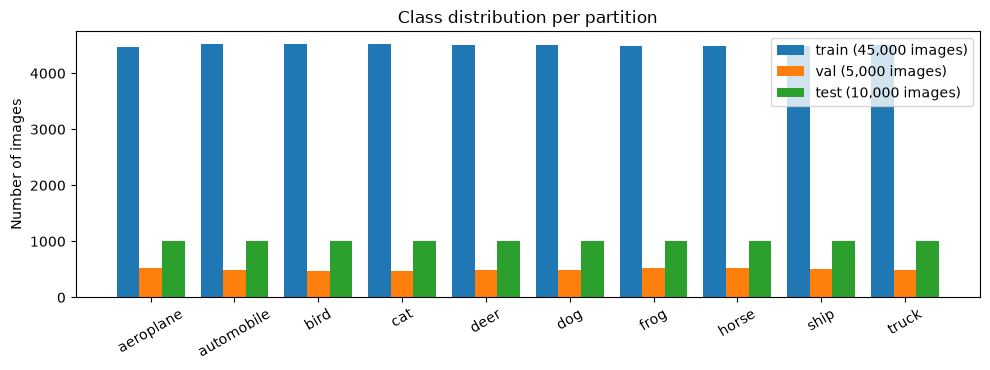

Files already downloaded and verified


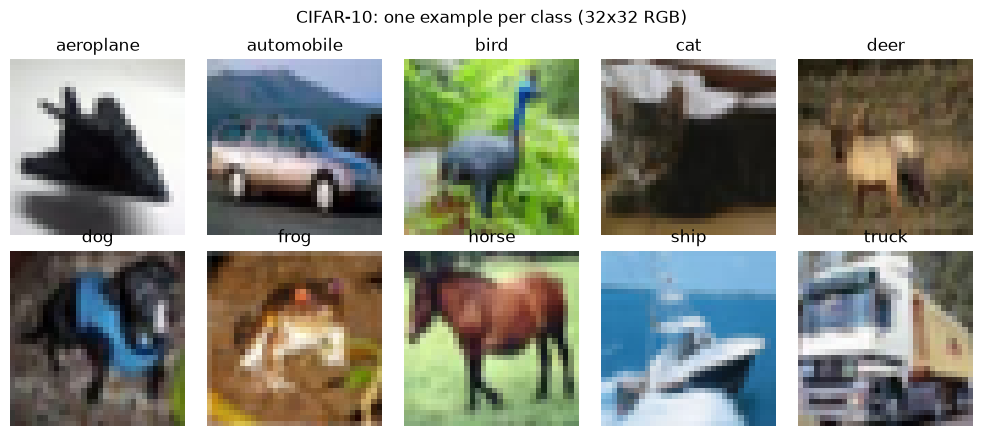

In [3]:
def class_counts(loader):
    """Number of images per class held by a GPULoader partition."""
    return np.bincount(loader.targets.cpu().numpy(), minlength=len(CLASSES))

counts = {name: class_counts(loaders[name]) for name in ("train", "val", "test")}

x, w = np.arange(len(CLASSES)), 0.27
plt.figure(figsize=(10, 3.8))
for i, (name, c) in enumerate(counts.items()):
    plt.bar(x + (i - 1) * w, c, w, label=f"{name} ({c.sum():,} images)")
plt.xticks(x, CLASSES, rotation=30)
plt.ylabel("Number of images")
plt.title("Class distribution per partition")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "class_distribution.png"), dpi=200)
plt.show()

# One example image per class
raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_targets = np.array(raw.targets)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(raw[int(np.where(raw_targets == c)[0][0])][0])
    ax.set_title(CLASSES[c])
    ax.axis("off")
fig.suptitle("CIFAR-10: one example per class (32x32 RGB)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "cifar10_samples.png"), dpi=200)
plt.show()

## 3. Helper functions

* `fit` trains with **Adam** and **cross-entropy loss**, records loss and accuracy per epoch, and restores the weights of the epoch with the best **validation** accuracy.
* `evaluate` / `final_evaluation` compute loss and accuracy; the test set is only used in `final_evaluation`, after training has finished.
* Plotting and saving utilities produce the figures and JSON results used in the report.

In [4]:
def count_parameters(model):
    """Number of trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, loader):
    """Mean cross-entropy loss and accuracy of `model` on `loader` (eval mode: no dropout)."""
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        total_loss += criterion(out, y).item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE, weight_decay=0.0, verbose=True):
    """Train with Adam + cross-entropy. After every epoch the model is scored on the validation set; the
    weights of the epoch with the highest validation accuracy are restored at the end (model selection
    uses validation data only -- never the test set). Running loss/accuracy are accumulated as GPU
    tensors and only moved to the CPU once per epoch (`.item()`), instead of after every batch, since a
    host-device sync on every step would otherwise stall the GPU pipeline."""
    criterion = nn.CrossEntropyLoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        run_loss = torch.zeros((), device=DEVICE)
        run_correct = torch.zeros((), device=DEVICE)
        seen = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimiser.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimiser.step()
            run_loss += loss.detach() * y.size(0)
            run_correct += (out.argmax(1) == y).sum()
            seen += y.size(0)

        history["train_loss"].append((run_loss / seen).item())
        history["train_acc"].append((run_correct / seen).item())
        val_loss, val_acc = evaluate(model, val_loader)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        if verbose:
            print(f"Epoch {epoch:02d}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
                  f"acc {history['train_acc'][-1]:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

    model.load_state_dict(best_state)
    return history, best_epoch, time.time() - start

def final_evaluation(model, loaders):
    """Loss / accuracy on the clean training images, the validation set and the test set."""
    result = {}
    for key, loader_name in (("train", "train_clean"), ("val", "val"), ("test", "test")):
        loss, acc = evaluate(model, loaders[loader_name])
        result[f"{key}_loss"], result[f"{key}_acc"] = loss, acc
    return result

def print_final(final):
    """Print the loss and accuracy of each partition and the train - test gap."""
    print(f"{'Partition':<12}{'Loss':>8}{'Accuracy':>11}")
    for part in ("train", "val", "test"):
        print(f"{part:<12}{final[part + '_loss']:>8.4f}{final[part + '_acc'] * 100:>10.2f}%")
    gap = (final["train_acc"] - final["test_acc"]) * 100
    print(f"Generalisation gap (train - test accuracy): {gap:.2f} percentage points")

def plot_history(history, best_epoch, title, filename):
    """Training vs validation loss (left) and accuracy (right)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["train_loss"], label="Training loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    axes[1].plot(epochs, history["train_acc"], label="Training accuracy")
    axes[1].plot(epochs, history["val_acc"], label="Validation accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
    for ax in axes:
        ax.axvline(best_epoch, ls="--", c="grey", label=f"Selected epoch ({best_epoch})")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()

@torch.no_grad()
def predict(model, loader):
    """Predicted and true class labels for every image in `loader` (eval mode)."""
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        preds.append(model(x.to(DEVICE)).argmax(1).cpu())
        labels.append(y.cpu())
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

def plot_confusion_matrix(model, loader, title, filename):
    """Confusion matrix (rows = true class, columns = predicted class). Returns the count matrix."""
    preds, labels = predict(model, loader)
    cm = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    np.add.at(cm, (labels, preds), 1)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set(xticks=range(len(CLASSES)), yticks=range(len(CLASSES)), xlabel="Predicted class",
           ylabel="True class", title=title)
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()
    return cm

def save_results(name, payload):
    """Write results to results/<name>.json (used for the tables and graphs in the report)."""
    path = os.path.join(RESULTS_DIR, f"{name}.json")
    with open(path, "w") as f:
        json.dump(payload, f, indent=2)
    print("Saved", path)

### Multi-seed protocol

Every configuration is trained from scratch with the run seeds in `SEEDS` (42, 43, 44). The train/validation split never changes (`SPLIT_SEED`); a run seed controls only weight initialisation, dropout and augmentation randomness, and the shuffling of the training batches. Results are reported as **mean ± sample standard deviation** over the three seeds. With only three seeds the standard deviation is itself a rough estimate, so small differences should be read cautiously.

* `run_experiment` trains one model and returns its final metrics, selected epoch, history, training time and parameter count.
* `summarise` gives the mean and standard deviation of every metric over a list of runs.

In [5]:
from IPython.display import Markdown, display

# Chart colours: one fixed categorical order, recessive ink and grid
INK, SECONDARY_INK, MUTED_INK = "#0b0b0b", "#52514e", "#898781"
GRID_COLOUR, AXIS_COLOUR = "#e1e0d9", "#c3c2b7"
SERIES = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100")
LIGHT_BLUE, DARK_BLUE = "#86b6ef", "#184f95"

def run_experiment(make_model, augment=None, seed=SEED, epochs=EPOCHS, lr=LEARNING_RATE, weight_decay=0.0):
    """Train one model from scratch with one run seed and evaluate the selected (best validation) epoch."""
    set_seed(seed)
    model = make_model().to(DEVICE)
    data = build_data(augment=augment, seed=seed)
    history, best_epoch, train_seconds = fit(model, data["train"], data["val"], epochs=epochs, lr=lr,
                                             weight_decay=weight_decay, verbose=False)
    return {
        "seed": seed,
        "final": final_evaluation(model, data),
        "best_epoch": best_epoch,
        "history": history,
        "train_seconds": train_seconds,
        "trainable_parameters": count_parameters(model),
    }

def run_metrics(run):
    """Scalar metrics of one run, including the gaps and the running loss at the selected epoch."""
    final = run["final"]
    return {
        **final,
        "gap": final["train_acc"] - final["test_acc"],            # generalisation gap
        "train_val_gap": final["train_acc"] - final["val_acc"],   # overfitting gap (no test data involved)
        "running_train_loss": run["history"]["train_loss"][run["best_epoch"] - 1],
        "best_epoch": run["best_epoch"],
        "train_seconds": run["train_seconds"],
        "seconds_per_epoch": run["train_seconds"] / len(run["history"]["train_loss"]),
        "trainable_parameters": run["trainable_parameters"],
    }

def summarise(runs):
    """Mean and sample standard deviation (ddof=1) of every metric over a list of runs."""
    rows = [run_metrics(run) for run in runs]
    return {key: {"mean": float(np.mean([row[key] for row in rows])),
                  "std": float(np.std([row[key] for row in rows], ddof=1)) if len(rows) > 1 else 0.0}
            for key in rows[0]}

def run_seeds(name, make_model, augment=None, seeds=SEEDS, **config):
    """Run one configuration once per seed. Progress shows validation accuracy only."""
    runs = []
    for seed in seeds:
        run = run_experiment(make_model, augment=augment, seed=seed)
        run["config"] = {"name": name, **config}
        runs.append(run)
        print(f"{name:<34} seed {seed} | selected epoch {run['best_epoch']:2d} | "
              f"val acc {run['final']['val_acc'] * 100:.2f}% | {run['train_seconds']:.1f} s")
    return runs

def pm(stat, scale=100, digits=2):
    """Format a summary statistic as 'mean ± std'."""
    return f"{stat['mean'] * scale:.{digits}f} ± {stat['std'] * scale:.{digits}f}"

def show_table(headers, rows):
    """Render a table as Markdown in the notebook output."""
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def curve_stats(runs, key):
    """Per-epoch mean and sample standard deviation of one history curve."""
    curves = np.array([run["history"][key] for run in runs])
    return curves.mean(axis=0), curves.std(axis=0, ddof=1)

def style_axes(ax, grid="y"):
    """Hairline grid behind the marks, no top or right spines, muted ticks."""
    ax.set_axisbelow(True)
    ax.grid(axis=grid, color=GRID_COLOUR, linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS_COLOUR)
    ax.tick_params(colors=SECONDARY_INK, length=3, color=AXIS_COLOUR)


## 4. Model: parametrised CNN and complexity

`make_cnn(channels)` builds one block (3x3 convolution with padding 1, ReLU, 2x2 max-pooling) per entry in `channels`, followed by `Flatten` and a single `Linear` classifier.

* **Depth** is the number of convolutional blocks.
* **Width** is the number of kernels in each block.
* The Exercise 2 baseline is `channels=(32, 64)`; the code asserts that it has exactly 60,362 parameters.

Six variations are compared with the baseline: three widths at depth 2, and three depths with doubling channels. Note that the final linear layer changes size with the architecture: pooling more often shrinks the flattened feature vector, so a deeper network can have **fewer** parameters than a shallower one.

**MACs** (multiply-accumulates) estimate the arithmetic of one forward pass and are counted with forward hooks. For a convolution this is `output height x output width x kernel area x input channels x output channels`; for a linear layer it is `input features x output features`.

In [6]:
def make_cnn(channels, num_classes=len(CLASSES)):
    """CNN with one block (3x3 conv + ReLU + 2x2 max-pool) per entry in `channels`, then one linear classifier.
    Depth is the number of blocks; width is the number of kernels in each block."""
    layers, in_channels = [], 3
    for out_channels in channels:
        layers += [nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        in_channels = out_channels
    side = 32 // 2 ** len(channels)   # spatial size after the pooling layers
    layers += [nn.Flatten(), nn.Linear(channels[-1] * side ** 2, num_classes)]
    return nn.Sequential(*layers)

def count_macs(model, input_size=(1, 3, 32, 32)):
    """Estimated multiply-accumulates for one forward pass, counted with hooks on conv and linear layers."""
    counts, handles = [], []

    def conv_hook(module, _, output):
        """Add the MACs of one convolution: output pixels x kernel area x input x output channels."""
        height, width = output.shape[2:]
        kh, kw = module.kernel_size
        counts.append(height * width * kh * kw * module.in_channels * module.out_channels // module.groups)

    def linear_hook(module, _, __):
        """Add the MACs of one linear layer: input features x output features."""
        counts.append(module.in_features * module.out_features)

    for module in model.modules():
        if isinstance(module, nn.Conv2d):
            handles.append(module.register_forward_hook(conv_hook))
        elif isinstance(module, nn.Linear):
            handles.append(module.register_forward_hook(linear_hook))
    with torch.no_grad():
        model(torch.zeros(input_size))
    for handle in handles:
        handle.remove()
    return int(sum(counts))

BASELINE = (32, 64)
WIDTH_SWEEP = ((16, 32), (32, 64), (64, 128), (128, 256))
DEPTH_SWEEP = ((32,), (32, 64), (32, 64, 128), (32, 64, 128, 256))
SWEEPS = {"Width sweep (depth 2)": WIDTH_SWEEP, "Depth sweep (doubling channels)": DEPTH_SWEEP}
CONFIGS = ((16, 32), (64, 128), (128, 256), (32,), (32, 64, 128), (32, 64, 128, 256), BASELINE)   # six variations + baseline

def label(channels):
    """Short configuration label, for example '32-64'."""
    return "-".join(str(c) for c in channels)

assert count_parameters(make_cnn(BASELINE)) == 60_362, "make_cnn((32, 64)) must match the Exercise 2 CNN"
complexity = {c: {"parameters": count_parameters(make_cnn(c)), "macs": count_macs(make_cnn(c))} for c in CONFIGS}
print(make_cnn(BASELINE))
show_table(["Channels", "Conv blocks", "Parameters", "MACs per image"],
           [[label(c), len(c), f"{complexity[c]['parameters']:,}", f"{complexity[c]['macs']:,}"]
            for c in sorted(CONFIGS, key=lambda c: complexity[c]["parameters"])])


Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4096, out_features=10, bias=True)
)


| Channels | Conv blocks | Parameters | MACs per image |
|---|---|---|---|
| 16-32 | 2 | 25,578 | 1,642,496 |
| 32-64 | 2 | 60,362 | 5,644,288 |
| 32 | 1 | 82,826 | 966,656 |
| 32-64-128 | 3 | 113,738 | 10,342,400 |
| 64-128 | 2 | 157,578 | 20,725,760 |
| 32-64-128-256 | 4 | 398,666 | 15,050,752 |
| 128-256 | 2 | 462,602 | 79,200,256 |

## 5. Training

Every configuration is trained with the same split, optimiser, learning rate, batch size and number of epochs. The best validation epoch is restored for each run.

In [7]:
results = {c: run_seeds(label(c), lambda c=c: make_cnn(c), channels=list(c), depth=len(c),
                       macs=complexity[c]["macs"]) for c in CONFIGS}
summary = {c: summarise(runs) for c, runs in results.items()}


16-32                              seed 42 | selected epoch 17 | val acc 70.18% | 17.6 s


16-32                              seed 43 | selected epoch 11 | val acc 69.92% | 16.9 s


16-32                              seed 44 | selected epoch 21 | val acc 69.78% | 16.6 s


64-128                             seed 42 | selected epoch  8 | val acc 73.78% | 73.1 s


64-128                             seed 43 | selected epoch 11 | val acc 72.44% | 71.2 s


64-128                             seed 44 | selected epoch 12 | val acc 74.30% | 71.1 s


... (11 outputs left out)

32-64-128-256                      seed 44 | selected epoch  6 | val acc 76.36% | 44.2 s


32-64                              seed 42 | selected epoch 13 | val acc 72.38% | 27.4 s


32-64                              seed 43 | selected epoch 11 | val acc 72.42% | 27.4 s


32-64                              seed 44 | selected epoch 12 | val acc 72.48% | 27.4 s


## 6. Validation loss curves

Mean validation loss per epoch, with a band of one standard deviation over the seeds, for the extreme configurations of each sweep against the baseline.

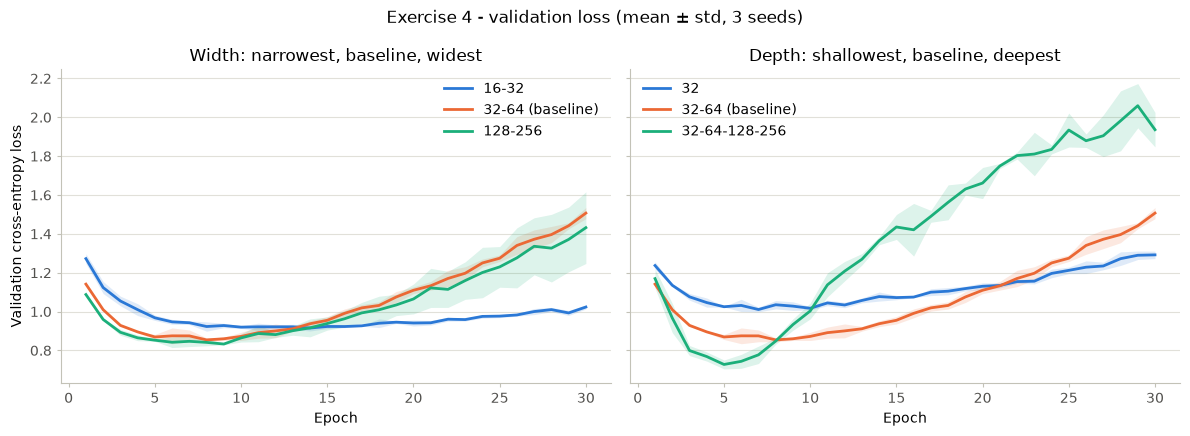

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
panels = (("Width: narrowest, baseline, widest", ((16, 32), BASELINE, (128, 256))),
          ("Depth: shallowest, baseline, deepest", ((32,), BASELINE, (32, 64, 128, 256))))
for ax, (title, chosen) in zip(axes, panels):
    for colour, c in zip(SERIES, chosen):
        mean, std = curve_stats(results[c], "val_loss")
        epochs = np.arange(1, len(mean) + 1)
        ax.plot(epochs, mean, color=colour, lw=2, label=label(c) + (" (baseline)" if c == BASELINE else ""))
        ax.fill_between(epochs, mean - std, mean + std, color=colour, alpha=0.15, linewidth=0)
    ax.set(xlabel="Epoch", title=title)
    style_axes(ax)
    ax.legend(frameon=False)
axes[0].set_ylabel("Validation cross-entropy loss")
fig.suptitle("Exercise 4 - validation loss (mean ± std, 3 seeds)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex4_val_curves.png"), dpi=200)
plt.show()


## 7. Final evaluation

The table reports the selected model of each run. **Running train loss** is the average loss during the selected training epoch, while the weights were still changing. **Clean train loss** is measured afterwards on the same training images with the selected weights in evaluation mode. Time per epoch includes the validation pass.

In [9]:
show_table(["Channels", "Parameters", "MACs (M)", "Val acc (%)", "Test acc (%)", "Running train loss", "Clean train loss",
            "Train - val gap (pts)", "Selected epoch", "Time / epoch (s)"],
           [[label(c) + (" (baseline)" if c == BASELINE else ""), f"{complexity[c]['parameters']:,}",
             f"{complexity[c]['macs'] / 1e6:.2f}", pm(summary[c]["val_acc"]), pm(summary[c]["test_acc"]),
             pm(summary[c]["running_train_loss"], 1, 3), pm(summary[c]["train_loss"], 1, 3),
             pm(summary[c]["train_val_gap"]), pm(summary[c]["best_epoch"], 1, 1), pm(summary[c]["seconds_per_epoch"], 1, 2)]
            for c in sorted(CONFIGS, key=lambda c: complexity[c]["parameters"])])

# The baseline configuration should reproduce the Exercise 3 baseline for the same seeds
ex3_path = os.path.join(RESULTS_DIR, "ex3_regularisation.json")
baseline_check = None
if not os.path.exists(ex3_path):
    print(f"{ex3_path} not found. Run Ex3_Regularisation.ipynb first to enable the baseline check.")
else:
    with open(ex3_path) as f:
        ex3 = json.load(f)
    ex3_baseline = {r["seed"]: r for r in ex3["runs"] if r["config"]["name"] == "Baseline"}
    rows, baseline_check = [], {}
    for run in results[BASELINE]:
        other = ex3_baseline[run["seed"]]
        same = run["final"] == other["final"] and run["best_epoch"] == other["best_epoch"] \
               and run["history"] == other["history"]
        baseline_check[str(run["seed"])] = same
        rows.append([run["seed"], f"{run['final']['val_acc'] * 100:.2f}", f"{other['final']['val_acc'] * 100:.2f}",
                     f"{run['final']['test_acc'] * 100:.2f}", f"{other['final']['test_acc'] * 100:.2f}",
                     "identical" if same else "DIFFERENT"])
    show_table(["Seed", "Ex4 val (%)", "Ex3 val (%)", "Ex4 test (%)", "Ex3 test (%)", "Metrics and history"], rows)


| Channels | Parameters | MACs (M) | Val acc (%) | Test acc (%) | Running train loss | Clean train loss | Train - val gap (pts) | Selected epoch | Time / epoch (s) |
|---|---|---|---|---|---|---|---|---|---|
| 16-32 | 25,578 | 1.64 | 69.96 ± 0.20 | 68.52 ± 0.16 | 0.674 ± 0.062 | 0.625 ± 0.071 | 8.69 ± 2.40 | 16.3 ± 5.0 | 0.57 ± 0.02 |
| 32-64 (baseline) | 60,362 | 5.64 | 72.43 ± 0.05 | 71.24 ± 0.06 | 0.492 ± 0.032 | 0.422 ± 0.034 | 13.45 ± 1.18 | 12.0 ± 1.0 | 0.91 ± 0.00 |
| 32 | 82,826 | 0.97 | 66.35 ± 0.50 | 65.19 ± 0.51 | 0.733 ± 0.029 | 0.664 ± 0.034 | 11.35 ± 1.29 | 10.7 ± 1.2 | 0.64 ± 0.02 |
| 32-64-128 | 113,738 | 10.34 | 75.59 ± 0.61 | 74.75 ± 0.57 | 0.389 ± 0.094 | 0.306 ± 0.085 | 14.46 ± 3.16 | 9.7 ± 2.1 | 1.12 ± 0.03 |
| 64-128 | 157,578 | 20.73 | 73.51 ± 0.96 | 72.19 ± 0.33 | 0.375 ± 0.101 | 0.304 ± 0.085 | 16.62 ± 2.52 | 10.3 ± 2.1 | 2.39 ± 0.04 |
| 32-64-128-256 | 398,666 | 15.05 | 76.11 ± 0.26 | 74.96 ± 0.35 | 0.233 ± 0.195 | 0.176 ± 0.161 | 18.22 ± 5.43 | 9.3 ± 3.1 | 1.41 ± 0.06 |
| 128-256 | 462,602 | 79.20 | 72.47 ± 0.21 | 72.21 ± 0.42 | 0.525 ± 0.068 | 0.447 ± 0.065 | 12.37 ± 2.07 | 11.0 ± 2.0 | 5.75 ± 0.01 |

| Seed | Ex4 val (%) | Ex3 val (%) | Ex4 test (%) | Ex3 test (%) | Metrics and history |
|---|---|---|---|---|---|
| 42 | 72.38 | 72.38 | 71.29 | 71.29 | identical |
| 43 | 72.42 | 72.42 | 71.17 | 71.17 | identical |
| 44 | 72.48 | 72.48 | 71.27 | 71.27 | identical |

## 8. Width and depth figures

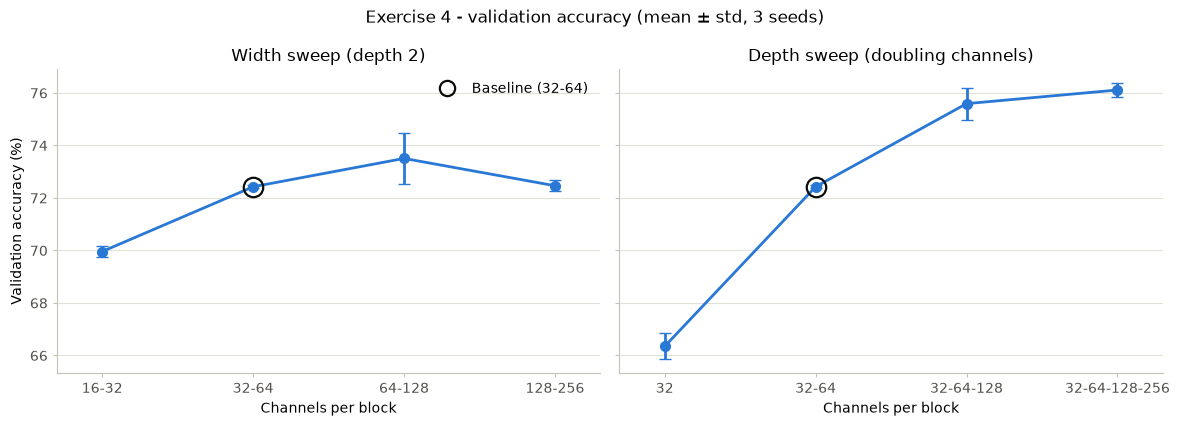

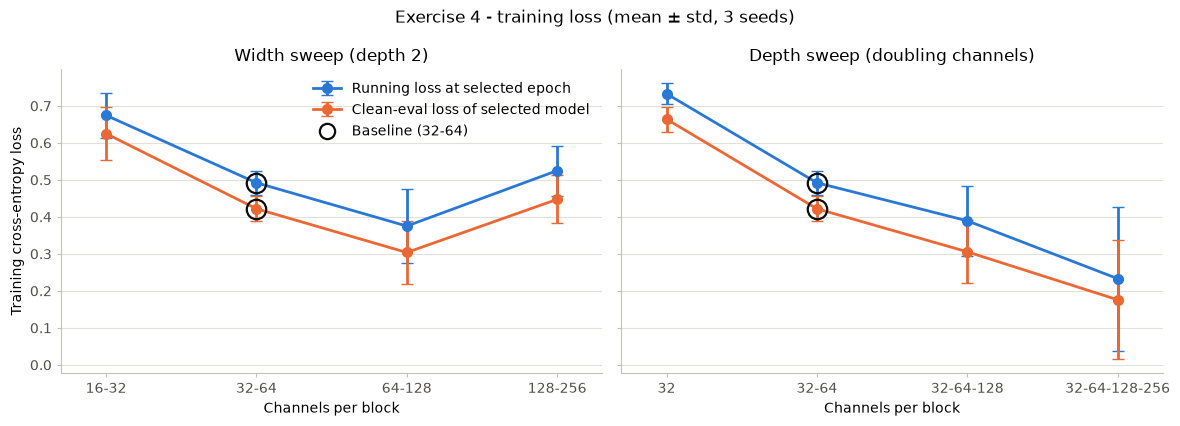

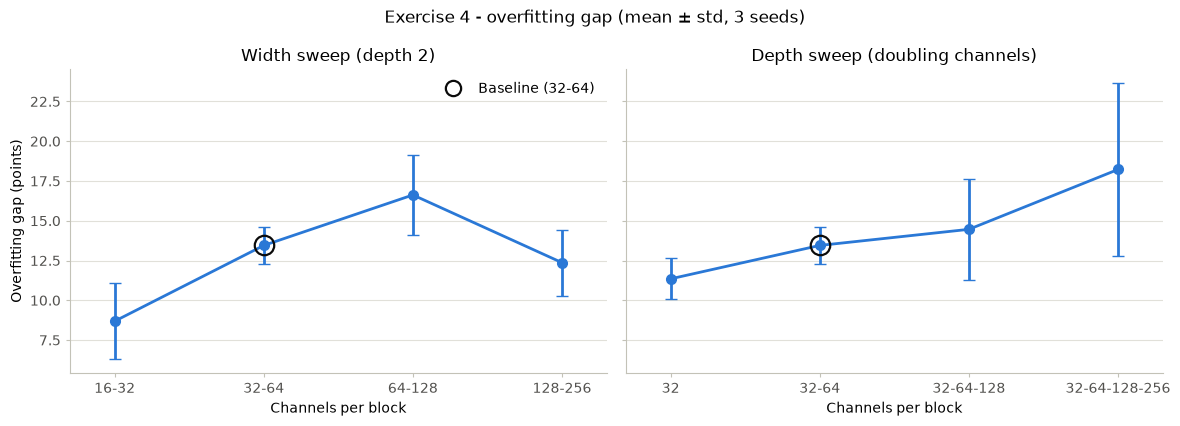

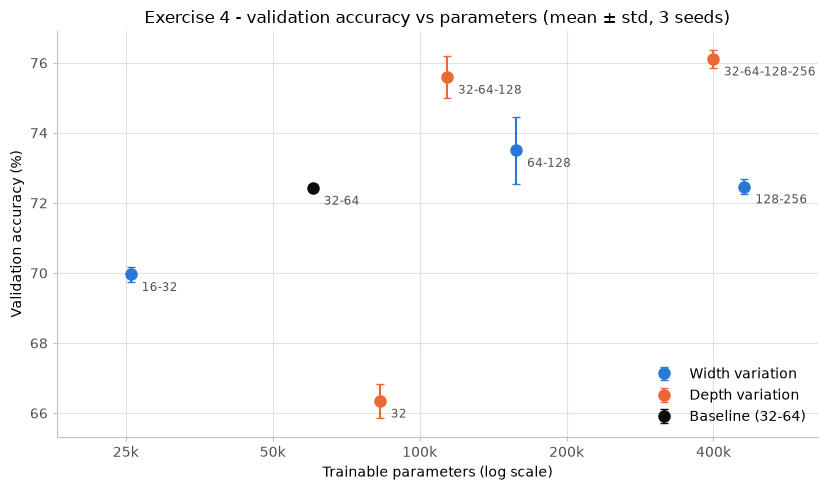

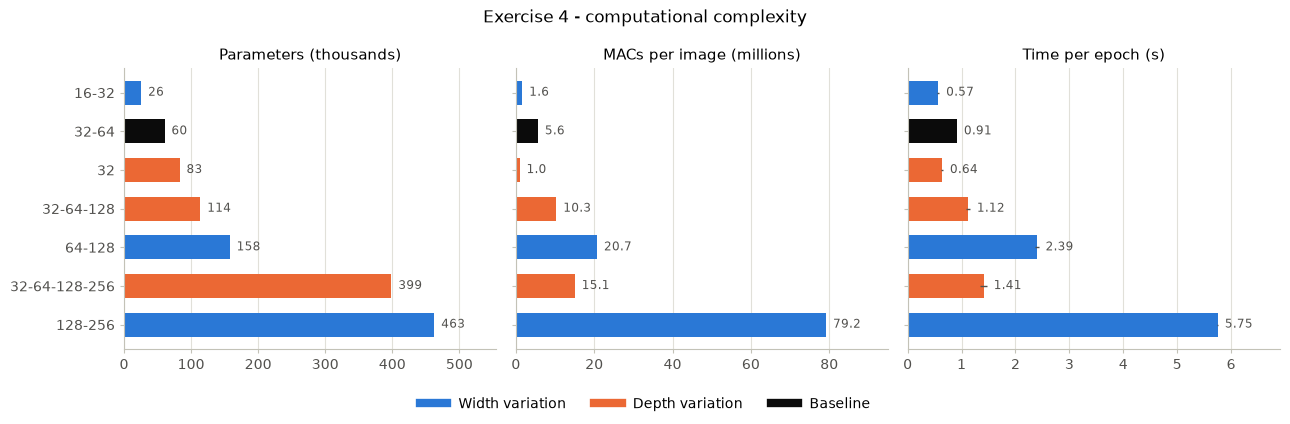

In [10]:
from matplotlib.lines import Line2D

def sweep_panels(series, ylabel, title, filename, scale=100):
    """Two panels (width sweep, depth sweep) of mean ± std per configuration, with the baseline ringed."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
    for ax, (sweep_name, sweep) in zip(axes, SWEEPS.items()):
        pos = np.arange(len(sweep))
        for metric, name, colour in series:
            means = np.array([summary[c][metric]["mean"] for c in sweep]) * scale
            stds = np.array([summary[c][metric]["std"] for c in sweep]) * scale
            ax.errorbar(pos, means, yerr=stds, marker="o", ms=7, lw=2, capsize=4, color=colour, label=name)
            i = sweep.index(BASELINE)
            ax.plot(pos[i], means[i], "o", ms=14, mfc="none", mec=INK, mew=1.6, zorder=5)
        ax.set(xticks=pos, xticklabels=[label(c) for c in sweep], xlabel="Channels per block", title=sweep_name)
        ax.margins(x=0.1)
        style_axes(ax)
    axes[0].set_ylabel(ylabel)
    handles, labels = axes[0].get_legend_handles_labels()
    ring = Line2D([], [], marker="o", ms=11, mfc="none", mec=INK, mew=1.6, ls="none")
    if len(series) == 1:
        handles, labels = [], []
    axes[0].legend(handles + [ring], labels + ["Baseline (32-64)"], frameon=False)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()

sweep_panels([("val_acc", "Validation accuracy", SERIES[0])], "Validation accuracy (%)",
             "Exercise 4 - validation accuracy (mean ± std, 3 seeds)", "ex4_val_accuracy.png")
sweep_panels([("running_train_loss", "Running loss at selected epoch", SERIES[0]),
              ("train_loss", "Clean-eval loss of selected model", SERIES[1])], "Training cross-entropy loss",
             "Exercise 4 - training loss (mean ± std, 3 seeds)", "ex4_train_loss.png", scale=1)
sweep_panels([("train_val_gap", "Train - validation accuracy", SERIES[0])], "Overfitting gap (points)",
             "Exercise 4 - overfitting gap (mean ± std, 3 seeds)", "ex4_overfitting_gap.png")

# Accuracy against parameters (log x), one colour per sweep and the baseline in ink
fig, ax = plt.subplots(figsize=(8.5, 5))
families = (("Width variation", [c for c in WIDTH_SWEEP if c != BASELINE], SERIES[0]),
            ("Depth variation", [c for c in DEPTH_SWEEP if c != BASELINE], SERIES[1]),
            ("Baseline (32-64)", [BASELINE], INK))
for name, members, colour in families:
    ax.errorbar([complexity[c]["parameters"] for c in members], [summary[c]["val_acc"]["mean"] * 100 for c in members],
                yerr=[summary[c]["val_acc"]["std"] * 100 for c in members], fmt="o", ms=8, capsize=3,
                color=colour, label=name)
    for c in members:
        ax.annotate(label(c), (complexity[c]["parameters"], summary[c]["val_acc"]["mean"] * 100),
                    xytext=(8, -12), textcoords="offset points", fontsize=8.5, color=SECONDARY_INK)
ax.set_xscale("log")
ax.set_xticks([25_000, 50_000, 100_000, 200_000, 400_000], ["25k", "50k", "100k", "200k", "400k"])
ax.minorticks_off()
ax.margins(x=0.12)
ax.set(xlabel="Trainable parameters (log scale)", ylabel="Validation accuracy (%)",
       title="Exercise 4 - validation accuracy vs parameters (mean ± std, 3 seeds)")
style_axes(ax, grid="both")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex4_accuracy_vs_parameters.png"), dpi=200)
plt.show()

# Complexity: parameters, MACs and measured time per epoch
order = sorted(CONFIGS, key=lambda c: complexity[c]["parameters"])
ypos = np.arange(len(order))
colours = [INK if c == BASELINE else (SERIES[0] if len(c) == 2 else SERIES[1]) for c in order]
panels = (("Parameters (thousands)", [complexity[c]["parameters"] / 1e3 for c in order], None, "{:.0f}"),
          ("MACs per image (millions)", [complexity[c]["macs"] / 1e6 for c in order], None, "{:.1f}"),
          ("Time per epoch (s)", [summary[c]["seconds_per_epoch"]["mean"] for c in order],
           [summary[c]["seconds_per_epoch"]["std"] for c in order], "{:.2f}"))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, (title, values, errors, fmt) in zip(axes, panels):
    bars = ax.barh(ypos, values, 0.62, xerr=errors, color=colours, error_kw={"elinewidth": 1, "ecolor": SECONDARY_INK})
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=5, fontsize=8.5, color=SECONDARY_INK)
    ax.set_title(title, fontsize=11)
    ax.margins(x=0.2)
    style_axes(ax, grid="x")
axes[0].set_yticks(ypos, [label(c) for c in order])
axes[0].invert_yaxis()
fig.legend(handles=[Line2D([], [], color=SERIES[0], lw=6, label="Width variation"),
                    Line2D([], [], color=SERIES[1], lw=6, label="Depth variation"),
                    Line2D([], [], color=INK, lw=6, label="Baseline")], frameon=False, loc="lower center", ncol=3)
fig.suptitle("Exercise 4 - computational complexity")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(os.path.join(FIG_DIR, "ex4_complexity.png"), dpi=200)
plt.show()


## 9. Discussion

Figures are mean ± std over three seeds. Comparisons use **validation** accuracy, and changes are paired with the baseline run of the same seed. Test accuracy is reported only.

**Depth**

* Depth has the clearest effect. Validation accuracy rises from 66.35% with one block to 72.43% (two), 75.59% (three) and 76.11% (four). Against the baseline, the changes are -6.08 ± 0.49, +3.17 ± 0.58 and +3.69 ± 0.24 points.
* Most of the gain arrives with the third block; the fourth adds only 0.52 ± 0.35 points.
* The cost is moderate: the four-block network needs 2.7 times the MACs and 1.6 times the training time per epoch of the baseline.

**Width**

* Halving the width (16-32) costs 2.47 ± 0.25 points.
* Doubling it (64-128) gains 1.08 ± 0.94 points, only just beyond one standard deviation and close to zero for seed 43 (+0.02), so this is weak evidence of a benefit.
* Quadrupling it (128-256) shows **no measurable gain** (+0.04 ± 0.26) for 14 times the MACs and 6.7 times the time per epoch.
* This should not be read as a limit of width itself. The 128-256 model fits the training data more slowly than 64-128 (running loss at epoch 30: 0.203 against 0.067), which is unexpected for a larger model. Every configuration uses the same learning rate of 1e-3, and this may be too high for a model whose final layer receives 16,384 features. The width conclusions therefore apply to this fixed learning rate.

**Complexity and accuracy**

* Parameter count alone is a poor guide. The one-block network has more parameters than the baseline (82,826 against 60,362), 98.9% of them in its linear layer, yet it has the lowest accuracy.
* Adding depth is the better use of computation here: the four-block network uses fewer MACs than 64-128 (15.05M against 20.73M) and is 2.61 ± 0.70 points more accurate.
* Training time grows with MACs, but less than proportionally, because each epoch also includes fixed costs such as batching, optimiser updates and validation.

**Training behaviour and overfitting**

* The clean training loss of the selected model falls steadily with depth (0.664, 0.422, 0.306, 0.176). The running loss is always higher because it is averaged while the weights are still changing during the epoch.
* The train - validation gap grows with depth from 11.35 to 18.22 points, but its spread is large for the deeper models (± 3.16 and ± 5.43), so this trend should be read with caution. The width sweep shows no consistent trend (8.69, 13.45, 16.62, 12.37), and its error bars overlap.
* The validation curves show overfitting most clearly: the deepest model reaches its lowest mean validation loss at epoch 5, then climbs steeply. Restoring the best validation epoch protects the reported results from this later decline.

**Limitations**

* All configurations share one learning rate, no regularisation and a 30-epoch budget, so each architecture is compared under the same conditions rather than at its own best settings.
* Three seeds give only a rough estimate of the spread. Times were measured on one laptop GPU, include the validation pass, and are indicative only.

## 10. Save results

`results/ex4_width_depth.json` stores every individual run and the aggregated summary used in the report.

In [11]:
all_runs = [run for runs in results.values() for run in runs]
save_results("ex4_width_depth", {
    "experiment": "Exercise 4 - Width and depth",
    "config": {"seeds": list(SEEDS), "split_seed": SPLIT_SEED, "val_size": VAL_SIZE, "batch_size": BATCH_SIZE,
               "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "optimiser": "Adam", "loss": "CrossEntropyLoss"},
    "device": str(DEVICE),
    "std": "sample standard deviation (ddof=1) over seeds",
    "baseline": label(BASELINE),
    "baseline_matches_ex3": baseline_check,
    "complexity": {label(c): complexity[c] for c in CONFIGS},
    "summary": {label(c): summary[c] for c in CONFIGS},
    "runs": [{"config": r["config"], "seed": r["seed"], "metrics": run_metrics(r), "final": r["final"],
              "best_epoch": r["best_epoch"], "train_seconds": r["train_seconds"],
              "trainable_parameters": r["trainable_parameters"], "history": r["history"]} for r in all_runs],
})
print("Individual runs saved:", len(all_runs))


Saved results\ex4_width_depth.json
Individual runs saved: 21


---

## 11. EXTENSION (outside the main protocol): learning rate for wider models

**This section is an extension. The main results of this exercise are the learning-rate 1e-3 results in Sections 5 to 10, and nothing in those sections depends on this one.**

The main discussion found that the widest model (128-256) fitted the training data more slowly than 64-128, and suggested that the shared learning rate of 1e-3 may be too high for it. This extension trains the baseline (32-64), 64-128 and 128-256 at a **lower learning rate of 3e-4**, with the same three seeds, 30 epochs, split, optimiser, batch size and best-validation-epoch rule.

The learning-rate 1e-3 results are **loaded from `results/ex4_width_depth.json`** and are not retrained here. The lower learning rate is judged on **validation accuracy only**; test accuracy is reported and is not used for any choice.

### 11.1 Training at the lower learning rate

In [12]:
# EXTENSION ONLY: run_experiment already accepts `lr`; the main protocol above stays at LEARNING_RATE
EXT_LR = 3e-4
EXT_CONFIGS = (BASELINE, (64, 128), (128, 256))

ext_runs = {}
for c in EXT_CONFIGS:
    ext_runs[c] = []
    for seed in SEEDS:
        run = run_experiment(lambda c=c: make_cnn(c), seed=seed, lr=EXT_LR)
        run["config"] = {"name": label(c), "channels": list(c), "lr": EXT_LR}
        ext_runs[c].append(run)
        print(f"{label(c):<8} lr={EXT_LR:g} seed {seed} | selected epoch {run['best_epoch']:2d} | "
              f"val acc {run['final']['val_acc'] * 100:.2f}% | {run['train_seconds']:.1f} s")

# Learning rate 1e-3: loaded from the saved main results, not retrained
with open(os.path.join(RESULTS_DIR, "ex4_width_depth.json")) as f:
    ext_stored = json.load(f)
ext_reference = {c: sorted((r for r in ext_stored["runs"] if r["config"]["name"] == label(c)), key=lambda r: r["seed"])
                 for c in EXT_CONFIGS}
assert all([r["seed"] for r in runs] == list(SEEDS) for runs in ext_reference.values())
print(f"\nLoaded {sum(len(runs) for runs in ext_reference.values())} runs at lr={ext_stored['config']['learning_rate']:g} "
      "from results/ex4_width_depth.json")


32-64    lr=0.0003 seed 42 | selected epoch 23 | val acc 72.04% | 27.6 s


32-64    lr=0.0003 seed 43 | selected epoch 17 | val acc 71.10% | 27.4 s


32-64    lr=0.0003 seed 44 | selected epoch 29 | val acc 71.98% | 27.4 s


64-128   lr=0.0003 seed 42 | selected epoch 18 | val acc 73.82% | 74.8 s


64-128   lr=0.0003 seed 43 | selected epoch 15 | val acc 74.08% | 76.1 s


64-128   lr=0.0003 seed 44 | selected epoch 15 | val acc 74.32% | 75.0 s


128-256  lr=0.0003 seed 42 | selected epoch  8 | val acc 74.54% | 181.5 s


128-256  lr=0.0003 seed 43 | selected epoch 19 | val acc 75.04% | 181.4 s


128-256  lr=0.0003 seed 44 | selected epoch 10 | val acc 74.60% | 177.1 s

Loaded 9 runs at lr=0.001 from results/ex4_width_depth.json


### 11.2 Results

| Learning rate | Channels | Val acc (%) | Test acc (%, reported only) | Final train loss (last epoch) | Clean train loss (selected model) | Selected epoch |
|---|---|---|---|---|---|---|
| 1e-3 | 32-64 (baseline) | 72.43 ± 0.05 | 71.24 ± 0.06 | 0.192 ± 0.011 | 0.422 ± 0.034 | 12.0 ± 1.0 |
| 1e-3 | 64-128 | 73.51 ± 0.96 | 72.19 ± 0.33 | 0.067 ± 0.008 | 0.304 ± 0.085 | 10.3 ± 2.1 |
| 1e-3 | 128-256 | 72.47 ± 0.21 | 72.21 ± 0.42 | 0.203 ± 0.074 | 0.447 ± 0.065 | 11.0 ± 2.0 |
| 3e-4 | 32-64 (baseline) | 71.71 ± 0.53 | 70.91 ± 0.35 | 0.498 ± 0.003 | 0.547 ± 0.080 | 23.0 ± 6.0 |
| 3e-4 | 64-128 | 74.07 ± 0.25 | 73.09 ± 0.21 | 0.167 ± 0.005 | 0.383 ± 0.048 | 16.0 ± 1.7 |
| 3e-4 | 128-256 | 74.73 ± 0.27 | 73.26 ± 0.48 | 0.030 ± 0.022 | 0.267 ± 0.185 | 12.3 ± 5.9 |

| Channels | Val change, 3e-4 minus 1e-3 (pts) | Test change (pts, reported only) |
|---|---|---|
| 32-64 | -0.72 ± 0.53 * | -0.33 ± 0.29 * |
| 64-128 | 0.57 ± 0.93 | 0.90 ± 0.48 * |
| 128-256 | 2.26 ± 0.39 * | 1.05 ± 0.42 * |

| Width comparison (val acc, pts) | At lr 1e-3 | At lr 3e-4 |
|---|---|---|
| 64-128 minus 32-64 | 1.08 ± 0.94 * | 2.37 ± 0.60 * |
| 128-256 minus 32-64 | 0.04 ± 0.26 | 3.02 ± 0.80 * |
| 128-256 minus 64-128 | -1.04 ± 1.00 * | 0.65 ± 0.34 * |

* the mean paired difference is larger than one standard deviation of the differences


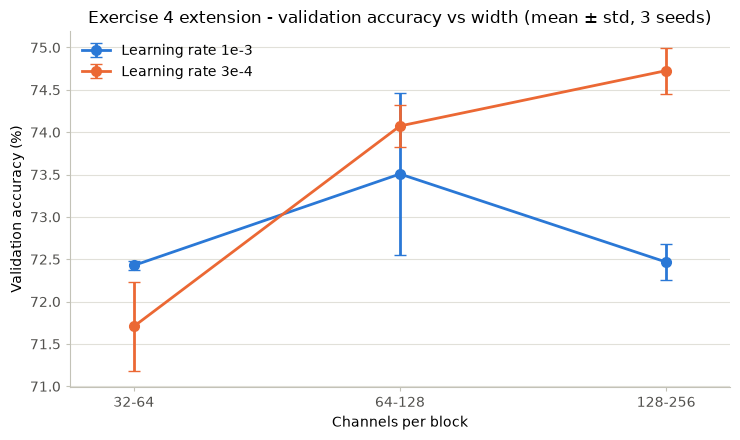

In [13]:
def ext_stat(values):
    """Mean and sample standard deviation of a list of per-seed values."""
    return {"mean": float(np.mean(values)), "std": float(np.std(values, ddof=1)) if len(values) > 1 else 0.0}

def ext_final_loss(runs):
    """Running training loss in the last epoch."""
    return ext_stat([run["history"]["train_loss"][-1] for run in runs])

def ext_paired(runs, reference, metric):
    """Per-seed difference (runs - reference) for one metric."""
    other = {run["seed"]: run_metrics(run)[metric] for run in runs}
    base = {run["seed"]: run_metrics(run)[metric] for run in reference}
    diffs = [other[seed] - base[seed] for seed in sorted(base)]
    return {**ext_stat(diffs), "per_seed": diffs}

def ext_flagged(diff):
    """Format a paired difference, marking it when its mean is larger than one standard deviation."""
    return pm(diff) + (" *" if abs(diff["mean"]) > diff["std"] else "")

EXT_RUNS_BY_LR = {"1e-3": ext_reference, "3e-4": ext_runs}
ext_summary = {lr: {c: summarise(runs) for c, runs in by_config.items()} for lr, by_config in EXT_RUNS_BY_LR.items()}

show_table(["Learning rate", "Channels", "Val acc (%)", "Test acc (%, reported only)", "Final train loss (last epoch)",
            "Clean train loss (selected model)", "Selected epoch"],
           [[lr, label(c) + (" (baseline)" if c == BASELINE else ""), pm(s["val_acc"]), pm(s["test_acc"]),
             pm(ext_final_loss(EXT_RUNS_BY_LR[lr][c]), 1, 3), pm(s["train_loss"], 1, 3), pm(s["best_epoch"], 1, 1)]
            for lr, by_config in ext_summary.items() for c, s in by_config.items()])

# Effect of the lower learning rate for each width, paired by seed
ext_lr_change = {c: {metric: ext_paired(ext_runs[c], ext_reference[c], metric) for metric in ("val_acc", "test_acc")}
                 for c in EXT_CONFIGS}
show_table(["Channels", "Val change, 3e-4 minus 1e-3 (pts)", "Test change (pts, reported only)"],
           [[label(c), ext_flagged(d["val_acc"]), ext_flagged(d["test_acc"])] for c, d in ext_lr_change.items()])

# Width conclusion at each learning rate, on validation accuracy only
ext_width_pairs = (((64, 128), BASELINE), ((128, 256), BASELINE), ((128, 256), (64, 128)))
ext_width_change = {lr: {f"{label(a)} minus {label(b)}": ext_paired(by_config[a], by_config[b], "val_acc")
                         for a, b in ext_width_pairs} for lr, by_config in EXT_RUNS_BY_LR.items()}
show_table(["Width comparison (val acc, pts)", "At lr 1e-3", "At lr 3e-4"],
           [[pair, ext_flagged(ext_width_change["1e-3"][pair]), ext_flagged(ext_width_change["3e-4"][pair])]
            for pair in ext_width_change["1e-3"]])
print("* the mean paired difference is larger than one standard deviation of the differences")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
positions = np.arange(len(EXT_CONFIGS))
for colour, lr in zip(SERIES, ext_summary):
    means = [ext_summary[lr][c]["val_acc"]["mean"] * 100 for c in EXT_CONFIGS]
    stds = [ext_summary[lr][c]["val_acc"]["std"] * 100 for c in EXT_CONFIGS]
    ax.errorbar(positions, means, yerr=stds, marker="o", ms=7, lw=2, capsize=4, color=colour, label=f"Learning rate {lr}")
ax.set(xticks=positions, xticklabels=[label(c) for c in EXT_CONFIGS], xlabel="Channels per block",
       ylabel="Validation accuracy (%)", title="Exercise 4 extension - validation accuracy vs width (mean ± std, 3 seeds)")
ax.margins(x=0.12)
style_axes(ax)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex4_ext_learning_rate.png"), dpi=200)
plt.show()


### 11.3 Notes

*This extension is outside the main protocol. The main results and discussion in Sections 5 to 10 are unchanged and remain the reported results for this exercise.* Figures are mean ± std over three seeds, and differences are paired by seed. Conclusions use **validation** accuracy; test accuracy is reported only.

**Does the width conclusion change? Yes.**

* In the main protocol (learning rate 1e-3), 128-256 showed no measurable gain over the baseline (+0.04 ± 0.26 points). At 3e-4, validation accuracy **rises with width**: 71.71% (32-64), 74.07% (64-128) and 74.73% (128-256).
* The lower learning rate helps the widest model most: +2.26 ± 0.39 points for 128-256. The change for 64-128 (+0.57 ± 0.93) is within one standard deviation, and the baseline is slightly worse (-0.72 ± 0.53).
* This supports the explanation suggested in the main discussion. At 3e-4 the final training loss of 128-256 falls from 0.203 to 0.030, so its slow fit at 1e-3 was linked to the learning rate rather than to a limit of width.

**A fair size for the width benefit**

* Comparing widths only at 3e-4 gives 128-256 a lead of 3.02 ± 0.80 points, but this **overstates the benefit** because the baseline itself is worse at 3e-4.
* Against the baseline at its better learning rate (1e-3), the wider models at 3e-4 gain **1.65 ± 0.20** points (64-128) and **2.30 ± 0.28** points (128-256). The corresponding test changes, reported only, are +1.85 ± 0.24 and +2.02 ± 0.52.
* Returns diminish: at 3e-4, 128-256 is 0.65 ± 0.34 points ahead of 64-128 but takes 2.4 times as long per epoch.

**Revised conclusion**

Extra width does improve accuracy when the learning rate suits the model, but at a high computational cost. 128-256 needs 14 times the MACs and about 6.6 times the time per epoch of the baseline for a gain of about 2.3 points. In the main protocol, the four-block network reached a higher validation accuracy (76.11%) with far fewer MACs (15.05M against 79.20M), although the deeper models were not re-tested at 3e-4, so this is not a like-for-like tuned comparison.

**Limitations**

* Only two learning rates were compared, so neither is shown to be the best for any model.
* The baseline at 3e-4 may be under-trained after 30 epochs: its selected epochs range from 17 to 29.
* Choosing the better learning rate on validation data makes those validation figures slightly optimistic, and three seeds give only a rough estimate of the spread. The test set was not used for any choice.

### 11.4 Save extension results

In [14]:
save_results("ex4_extension_lr", {
    "experiment": "Exercise 4 extension - learning rate for wider models",
    "protocol": "EXTENSION: outside the main protocol; the main results are in ex4_width_depth.json",
    "config": {"seeds": list(SEEDS), "split_seed": SPLIT_SEED, "val_size": VAL_SIZE, "batch_size": BATCH_SIZE,
               "epochs": EPOCHS, "extension_learning_rate": EXT_LR, "reference_learning_rate": ext_stored["config"]["learning_rate"],
               "reference_source": "results/ex4_width_depth.json (not retrained)", "optimiser": "Adam", "loss": "CrossEntropyLoss"},
    "device": str(DEVICE),
    "std": "sample standard deviation (ddof=1) over seeds",
    "selection_note": "the learning rate is judged on validation accuracy only; test accuracy is reported, not used",
    "summary": {lr: {label(c): {**s, "final_epoch_train_loss": ext_final_loss(EXT_RUNS_BY_LR[lr][c])}
                     for c, s in by_config.items()} for lr, by_config in ext_summary.items()},
    "lr_change_3e-4_minus_1e-3": {label(c): d for c, d in ext_lr_change.items()},
    "width_change_val_acc": ext_width_change,
    "runs": [{"config": r["config"], "seed": r["seed"], "metrics": run_metrics(r), "final": r["final"],
              "best_epoch": r["best_epoch"], "train_seconds": r["train_seconds"],
              "trainable_parameters": r["trainable_parameters"], "history": r["history"]}
             for runs in ext_runs.values() for r in runs],
})


Saved results\ex4_extension_lr.json
